# Calibracao Bayesiana 2D de uma distribuicao Gaussiana

Agora estimamos conjuntamente a media $\theta$ e o desvio-padrao $\sigma$ de uma distribuicao Gaussiana. A posterior e aproximada por Metropolis-Hastings com 100.000 iteracoes por cadeia.

## 1. Dados, likelihood e prioris

Assumimos $y_i \sim Normal(\theta, \sigma)$. As prioris sao uniformes: $\theta \sim Uniform(1.4, 1.5)$ e $\sigma \sim Uniform(10^{-5}, 10^{-2})$. Fora desses intervalos, a posterior vale zero.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

dados = np.array([1.466, 1.459, 1.461, 1.457, 1.464, 1.456, 1.457, 1.454])
theta_min, theta_max = 1.4, 1.5
sigma_min, sigma_max = 1.0e-5, 1.0e-2

print(f'Numero de observacoes: {dados.size}')
print(f'Media amostral: {dados.mean():.6f}')
print(f'DP amostral: {dados.std(ddof=1):.6f}')

Numero de observacoes: 8
Media amostral: 1.459250
DP amostral: 0.004132


## 2. Parametrizacao para a MCMC

A MCMC atualiza $\theta$ diretamente e $\eta = log(\sigma)$. Propor em $\eta$ garante que $\sigma = exp(\eta)$ seja sempre positivo. Como a cadeia vive no espaco $(\theta, \eta)$, a log-posterior inclui o termo $+\eta$, o jacobiano da transformacao de $\sigma$ para $log(\sigma)$.

In [9]:
if dados.size == 0 or not np.all(np.isfinite(dados)):
    raise ValueError('dados deve conter valores finitos.')
if not (theta_min < theta_max and 0 < sigma_min < sigma_max):
    raise ValueError('Limites das prioris invalidos.')

log_sigma_min = np.log(sigma_min)
log_sigma_max = np.log(sigma_max)

# Exemplo de log-posterior no centro aproximado dos dados.
theta_exemplo = dados.mean()
eta_exemplo = np.log(dados.std(ddof=1))
sigma_exemplo = np.exp(eta_exemplo)
log_likelihood_exemplo = (
    -dados.size * eta_exemplo
    - 0.5 * dados.size * np.log(2 * np.pi)
    - 0.5 * np.sum(((dados - theta_exemplo) / sigma_exemplo) ** 2)
)
log_alvo_exemplo = log_likelihood_exemplo + eta_exemplo
print(f'log-likelihood no exemplo: {log_likelihood_exemplo:.3f}')
print(f'log-alvo em (theta, log_sigma): {log_alvo_exemplo:.3f}')

log-likelihood no exemplo: 33.061
log-alvo em (theta, log_sigma): 27.572


## 3. Configurar as quatro cadeias

Cada cadeia recebe um estado inicial distinto. Em cada iteracao, propomos simultaneamente um novo $\theta$ e um novo $log(\sigma)$ com random walks Gaussianos. As escalas de proposta controlam o tamanho dos passos.

In [10]:
n_iteracoes = 100_000
burn_in = 10_000
passo_theta = 0.0008
passo_log_sigma = 0.15
iniciais_theta = [1.440, 1.450, 1.470, 1.480]
iniciais_sigma = [0.002, 0.004, 0.006, 0.008]

if n_iteracoes <= burn_in or passo_theta <= 0 or passo_log_sigma <= 0:
    raise ValueError('Configuracao da MCMC invalida.')

print(f'Iteracoes por cadeia: {n_iteracoes}')
print(f'Burn-in: {burn_in}')
print(f'Passos de proposta: theta={passo_theta}, log(sigma)={passo_log_sigma}')

Iteracoes por cadeia: 100000
Burn-in: 10000
Passos de proposta: theta=0.0008, log(sigma)=0.15


## 4. Executar Metropolis-Hastings 2D

Uma proposta fora dos limites das prioris e rejeitada. Para uma proposta valida, calculamos a diferenca entre os log-alvos e aceitamos quando $log(U) < min(0, \Delta)$. Os estados rejeitados tambem sao armazenados, pois a repeticao faz parte da cadeia de Markov.

In [11]:
cadeias_theta = []
cadeias_sigma = []
taxas_aceitacao = []

for indice_cadeia, (theta_inicial, sigma_inicial) in enumerate(zip(iniciais_theta, iniciais_sigma)):
    rng = np.random.default_rng(2026 + indice_cadeia)
    cadeia_theta = np.empty(n_iteracoes)
    cadeia_sigma = np.empty(n_iteracoes)
    theta_atual = theta_inicial
    eta_atual = np.log(sigma_inicial)
    sigma_atual = np.exp(eta_atual)
    log_alvo_atual = (
        -dados.size * eta_atual
        - 0.5 * dados.size * np.log(2 * np.pi)
        - 0.5 * np.sum(((dados - theta_atual) / sigma_atual) ** 2)
        + eta_atual
    )
    aceitos = 0

    for t in range(n_iteracoes):
        theta_proposto = rng.normal(theta_atual, passo_theta)
        eta_proposto = rng.normal(eta_atual, passo_log_sigma)

        if theta_min <= theta_proposto <= theta_max and log_sigma_min <= eta_proposto <= log_sigma_max:
            sigma_proposto = np.exp(eta_proposto)
            log_alvo_proposto = (
                -dados.size * eta_proposto
                - 0.5 * dados.size * np.log(2 * np.pi)
                - 0.5 * np.sum(((dados - theta_proposto) / sigma_proposto) ** 2)
                + eta_proposto
            )
            log_alpha = min(0.0, log_alvo_proposto - log_alvo_atual)

            if np.log(rng.uniform()) < log_alpha:
                theta_atual = theta_proposto
                eta_atual = eta_proposto
                sigma_atual = sigma_proposto
                log_alvo_atual = log_alvo_proposto
                aceitos += 1

        cadeia_theta[t] = theta_atual
        cadeia_sigma[t] = sigma_atual

    cadeias_theta.append(cadeia_theta)
    cadeias_sigma.append(cadeia_sigma)
    taxas_aceitacao.append(aceitos / n_iteracoes)

cadeias_theta = np.asarray(cadeias_theta)
cadeias_sigma = np.asarray(cadeias_sigma)
print(f'Taxas de aceitacao: {np.round(taxas_aceitacao, 3)}')

Taxas de aceitacao: [0.744 0.747 0.745 0.744]


## 5. Resumo posterior e diagnosticos

Descartamos o burn-in e combinamos as cadeias. R-hat compara a variabilidade entre cadeias com a variabilidade dentro delas. O ESS desconta a autocorrelacao, portanto mede aproximadamente quantas amostras independentes as cadeias representam.

In [12]:
amostras_theta_por_cadeia = cadeias_theta[:, burn_in:]
amostras_sigma_por_cadeia = cadeias_sigma[:, burn_in:]
amostras_theta = amostras_theta_por_cadeia.ravel()
amostras_sigma = amostras_sigma_por_cadeia.ravel()

def rhat(cadeias):
    numero_cadeias, draws = cadeias.shape
    variancia_entre = draws * np.var(cadeias.mean(axis=1), ddof=1)
    variancia_dentro = np.mean(np.var(cadeias, axis=1, ddof=1))
    return np.sqrt(((draws - 1) / draws * variancia_dentro + variancia_entre / draws) / variancia_dentro)

def ess(cadeias):
    resultado = 0.0
    for cadeia in cadeias:
        centrada = cadeia - cadeia.mean()
        denominador = np.dot(centrada, centrada)
        soma_rho = 0.0
        for lag in range(1, len(cadeia)):
            rho = np.dot(centrada[:-lag], centrada[lag:]) / denominador
            if rho <= 0:
                break
            soma_rho += rho
        resultado += len(cadeia) / (1 + 2 * soma_rho)
    return resultado

rhat_theta = rhat(amostras_theta_por_cadeia)
rhat_sigma = rhat(amostras_sigma_por_cadeia)
ess_theta = ess(amostras_theta_por_cadeia)
ess_sigma = ess(amostras_sigma_por_cadeia)

print(f'theta: media={amostras_theta.mean():.6f}, ICr 95%={np.quantile(amostras_theta, [0.025, 0.975])}')
print(f'sigma: media={amostras_sigma.mean():.6f}, ICr 95%={np.quantile(amostras_sigma, [0.025, 0.975])}')
print(f'R-hat: theta={rhat_theta:.3f}, sigma={rhat_sigma:.3f}')
print(f'ESS aproximado: theta={ess_theta:.0f}, sigma={ess_sigma:.0f}')

theta: media=1.459271, ICr 95%=[1.45558817 1.46298412]
sigma: media=0.004974, ICr 95%=[0.00286515 0.00868408]
R-hat: theta=1.000, sigma=1.000
ESS aproximado: theta=9074, sigma=13020


## 6. Tracos e PDFs marginais

Os tracos mostram a exploracao de cada parametro. Os histogramas normalizados aproximam as distribuicoes marginais posteriores: uma para $\theta$ e outra para $\sigma$.

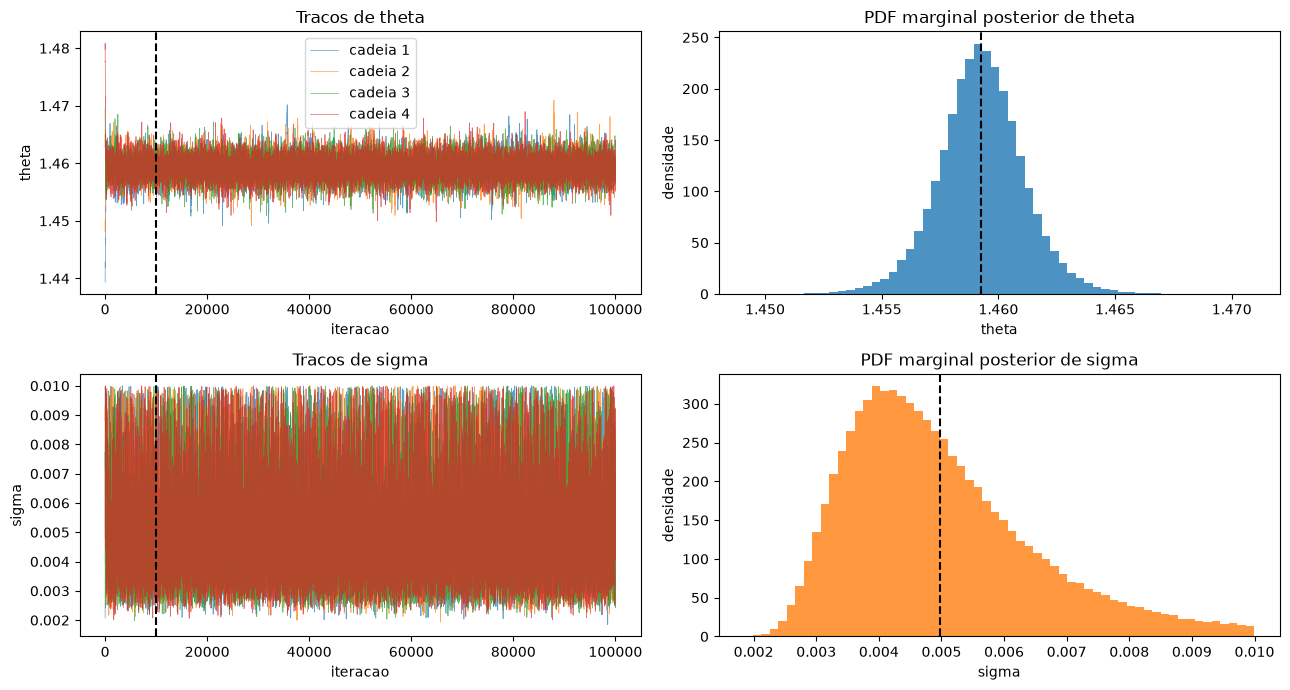

In [13]:
fig, eixos = plt.subplots(2, 2, figsize=(13, 7))
for numero, (theta, sigma) in enumerate(zip(cadeias_theta, cadeias_sigma), start=1):
    eixos[0, 0].plot(theta, linewidth=0.5, alpha=0.7, label=f'cadeia {numero}')
    eixos[1, 0].plot(sigma, linewidth=0.5, alpha=0.7, label=f'cadeia {numero}')
eixos[0, 0].axvline(burn_in, color='black', linestyle='--')
eixos[1, 0].axvline(burn_in, color='black', linestyle='--')
eixos[0, 0].set(title='Tracos de theta', xlabel='iteracao', ylabel='theta')
eixos[1, 0].set(title='Tracos de sigma', xlabel='iteracao', ylabel='sigma')
eixos[0, 0].legend()

eixos[0, 1].hist(amostras_theta, bins=60, density=True, color='C0', alpha=0.8)
eixos[0, 1].axvline(amostras_theta.mean(), color='black', linestyle='--')
eixos[0, 1].set(title='PDF marginal posterior de theta', xlabel='theta', ylabel='densidade')
eixos[1, 1].hist(amostras_sigma, bins=60, density=True, color='C1', alpha=0.8)
eixos[1, 1].axvline(amostras_sigma.mean(), color='black', linestyle='--')
eixos[1, 1].set(title='PDF marginal posterior de sigma', xlabel='sigma', ylabel='densidade')

plt.tight_layout()
plt.show()

## 7. Posterior conjunta

Cada ponto representa um par $(\theta, \sigma)$ visitado apos o burn-in. A nuvem mostra a dependencia entre os dois parametros que seria perdida ao olhar apenas as PDFs marginais.

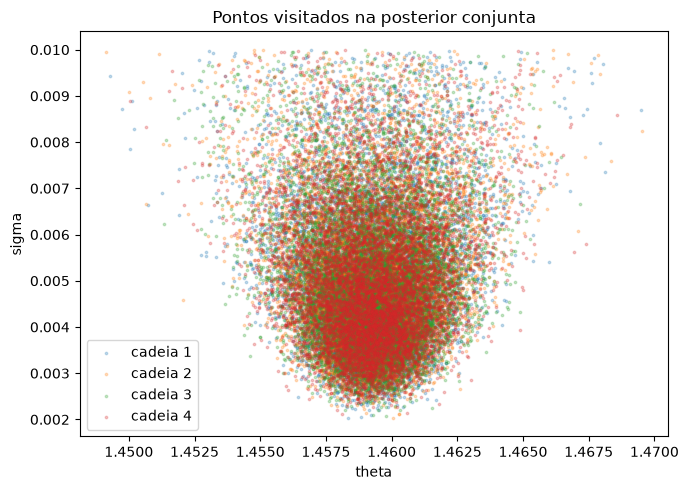

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for numero, (theta, sigma) in enumerate(zip(amostras_theta_por_cadeia, amostras_sigma_por_cadeia), start=1):
    ax.scatter(theta[::10], sigma[::10], s=3, alpha=0.25, label=f'cadeia {numero}')

ax.set(title='Pontos visitados na posterior conjunta', xlabel='theta', ylabel='sigma')
ax.legend()
plt.tight_layout()
plt.show()

## 8. Pontos visitados e PDF posterior conjunta em 3D

Usamos a primeira cadeia apos o burn-in. Os pontos na base sao estados realmente visitados pela MCMC, reduzidos para o grafico permanecer legivel. A superficie e uma estimativa por histograma 2D da PDF posterior conjunta de $\theta$ e $\sigma$.

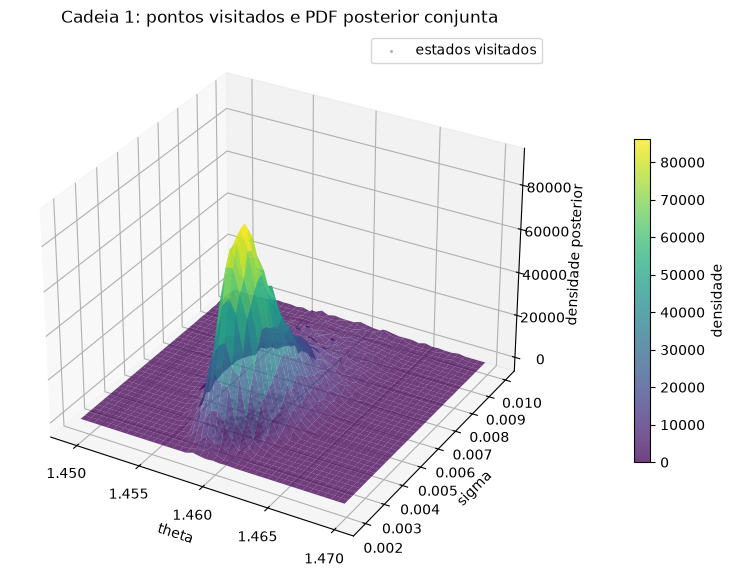

In [15]:
theta_cadeia_1 = amostras_theta_por_cadeia[0]
sigma_cadeia_1 = amostras_sigma_por_cadeia[0]

# A altura de cada celula do histograma aproxima a densidade posterior conjunta.
densidade_2d, bordas_theta, bordas_sigma = np.histogram2d(
    theta_cadeia_1, sigma_cadeia_1, bins=40, density=True
)
centros_theta = (bordas_theta[:-1] + bordas_theta[1:]) / 2
centros_sigma = (bordas_sigma[:-1] + bordas_sigma[1:]) / 2
grade_theta, grade_sigma = np.meshgrid(centros_theta, centros_sigma, indexing='ij')

fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(projection='3d')
superficie = ax.plot_surface(
    grade_theta, grade_sigma, densidade_2d, cmap='viridis',
    alpha=0.75, linewidth=0, antialiased=True
)

# Um em cada 20 pontos e mostrado para visualizar os estados sem sobrecarregar a figura.
ax.scatter(
    theta_cadeia_1[::20], sigma_cadeia_1[::20], 0,
    s=2, color='black', alpha=0.20, label='estados visitados'
)
ax.set(
    title='Cadeia 1: pontos visitados e PDF posterior conjunta',
    xlabel='theta', ylabel='sigma', zlabel='densidade posterior'
)
ax.legend()
fig.colorbar(superficie, ax=ax, shrink=0.6, pad=0.1, label='densidade')
plt.show()